In [100]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
import utils
import dynamics
import simulation

In [101]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [102]:
SEMI_MAJOR_AXIS = 6.778e6
GRAV = 3.986004418e14

In [103]:
initial_state = np.array([
    100.0,  # x, meters
    0.0,    # y
    0.0,    # z
    0.0,    # vx, m/s
    0.0,    # vy
    0.0,    # vz
]).reshape(6, 1)

n = dynamics.orbital_rate(SEMI_MAJOR_AXIS, GRAV)
dt = 0.01
T = 1000

t, X, U, X_est, attitude_history, wheel_torque, thruster_torque = simulation.simulate(n, initial_state, dt, T)

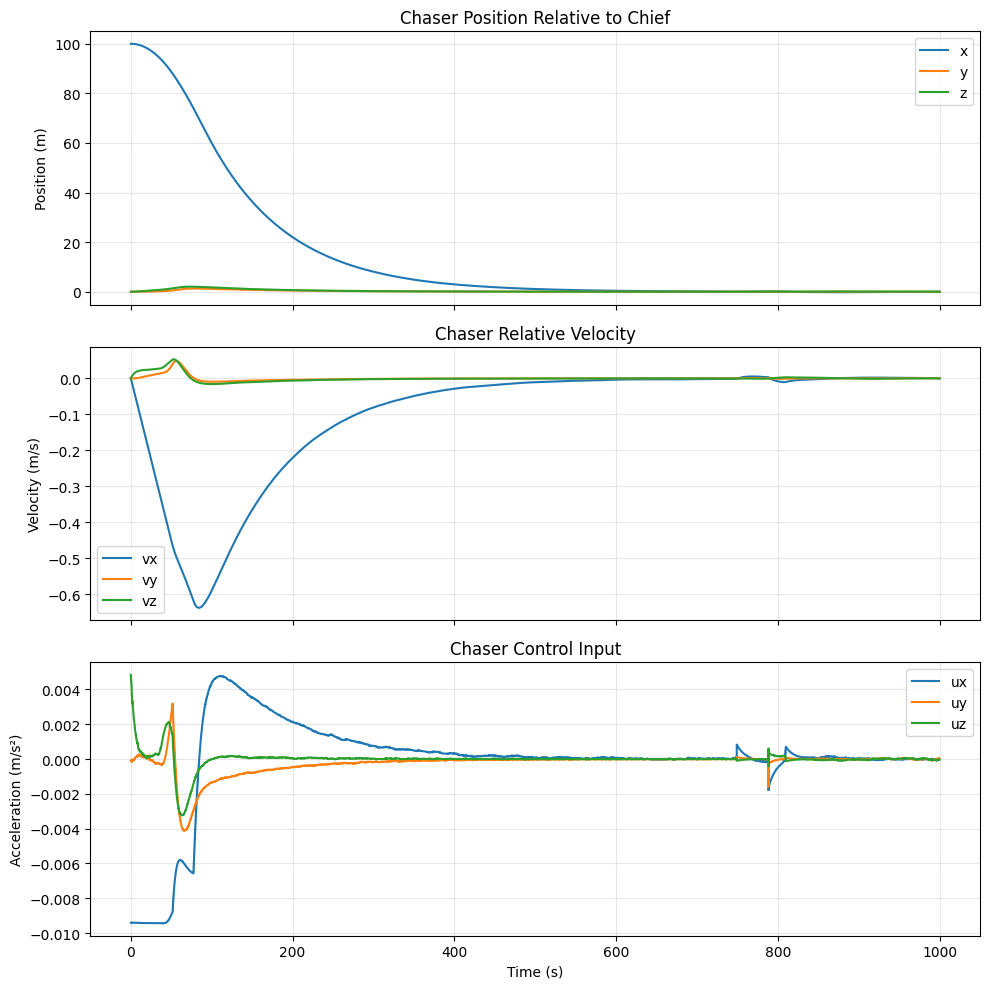

In [104]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

# Handles U with either len(t) or len(t)-1 samples.
t_control = t[:len(U)]

for i, axis in enumerate(("x", "y", "z")):
    axes[0].plot(t, X[:, i], label=axis)
    axes[1].plot(t, X[:, i + 3], label=f"v{axis}")
    axes[2].step(
        t_control, U[:, i],
        where="post", label=f"u{axis}"
    )

axes[0].set(
    title="Chaser Position Relative to Chief",
    ylabel="Position (m)",
)
axes[1].set(
    title="Chaser Relative Velocity",
    ylabel="Velocity (m/s)",
)
axes[2].set(
    title="Chaser Control Input",
    xlabel="Time (s)",
    ylabel="Acceleration (m/s²)",
)

for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)




fig.tight_layout()

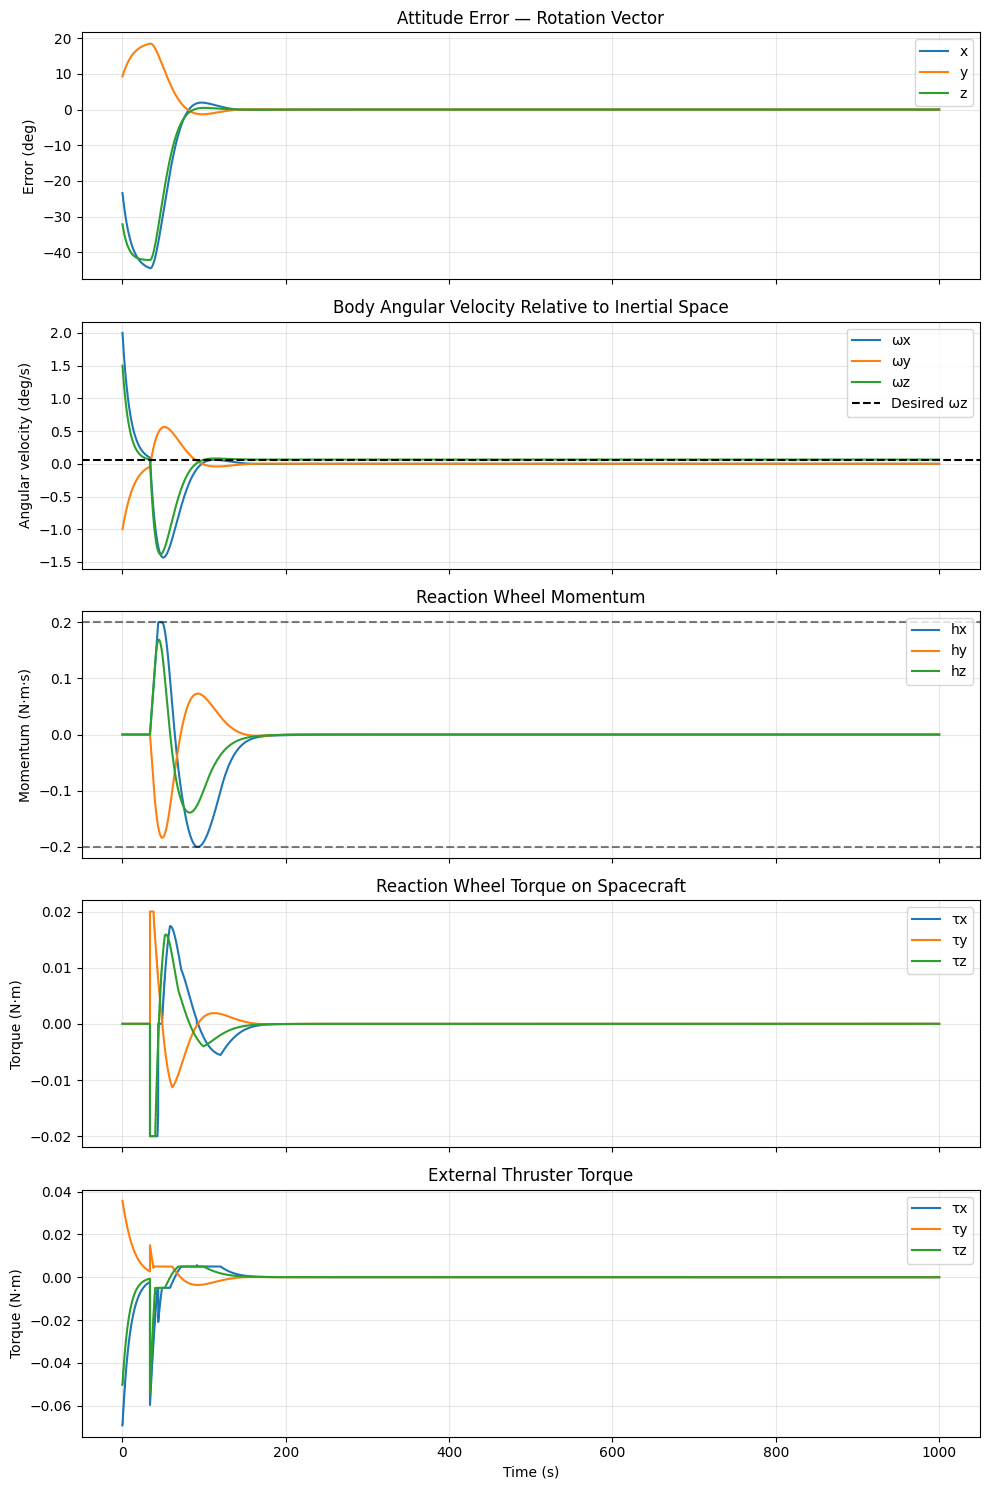

In [105]:
quaternions = attitude_history[:, :4]
angular_velocity = attitude_history[:, 4:7]
wheel_momentum = attitude_history[:, 7:10]

desired_rotation = Rotation.identity()
actual_rotation = Rotation.from_quat(quaternions)

attitude_error = (actual_rotation.inv() * desired_rotation).as_rotvec()

fig, axes = plt.subplots(5, 1, figsize=(10, 15), sharex=True)

for i, axis in enumerate(("x", "y", "z")):
    axes[0].plot(
        t, np.rad2deg(attitude_error[:, i]), label=axis
    )

    axes[1].plot(
        t, np.rad2deg(angular_velocity[:, i]), label=f"ω{axis}"
    )

    axes[2].plot(
        t, wheel_momentum[:, i], label=f"h{axis}"
    )

    axes[3].step(
        t[:len(wheel_torque)],
        wheel_torque[:, i],
        where="post", label=f"τ{axis}",
    )

    axes[4].step(
        t[:len(thruster_torque)],
        thruster_torque[:, i],
        where="post", label=f"τ{axis}",
    )

# Desired angular velocity at orbital alignment.
axes[1].axhline(
    np.rad2deg(n),
    color="black",
    linestyle="--",
    label="Desired ωz",
)

# Assumed wheel momentum limits from the simulation.
for limit in (-0.2, 0.2):
    axes[2].axhline(
        limit, color="black", linestyle="--", alpha=0.5
    )

axes[0].set(
    title="Attitude Error — Rotation Vector",
    ylabel="Error (deg)",
)
axes[1].set(
    title="Body Angular Velocity Relative to Inertial Space",
    ylabel="Angular velocity (deg/s)",
)
axes[2].set(
    title="Reaction Wheel Momentum",
    ylabel="Momentum (N·m·s)",
)
axes[3].set(
    title="Reaction Wheel Torque on Spacecraft",
    ylabel="Torque (N·m)",
)
axes[4].set(
    title="External Thruster Torque",
    xlabel="Time (s)",
    ylabel="Torque (N·m)",
)

for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

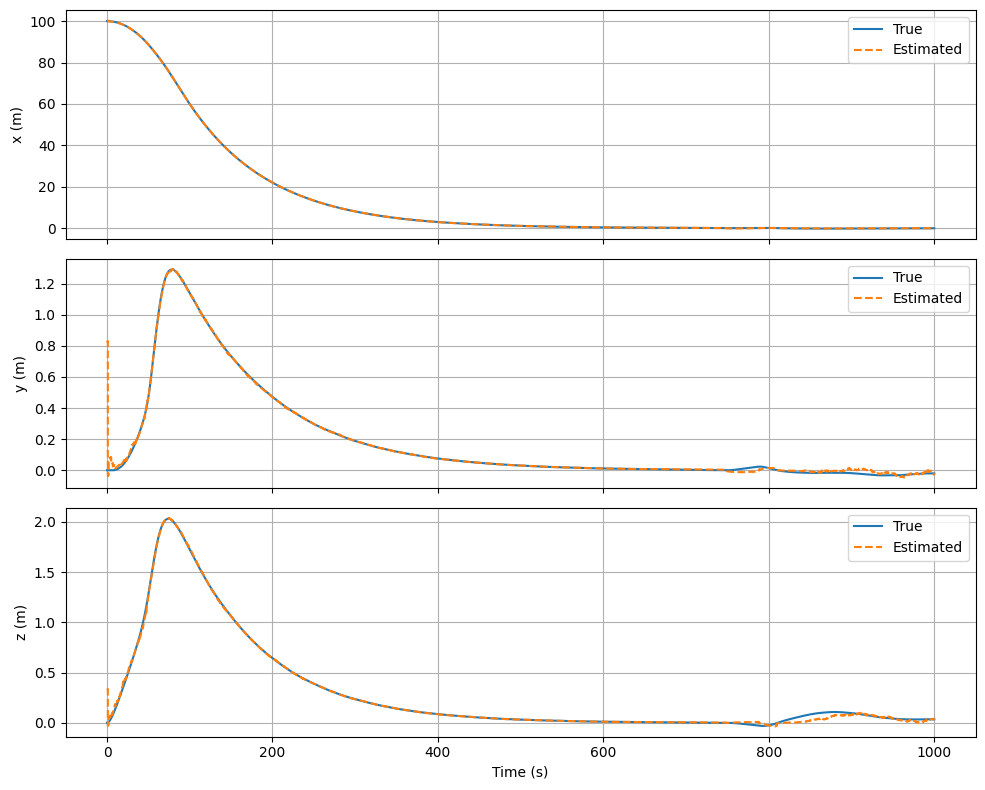

In [106]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for i, axis in enumerate(("x", "y", "z")):
    axes[i].plot(t, X[:, i], label="True")
    axes[i].plot(t, X_est[:, i], "--", label="Estimated")
    axes[i].set_ylabel(f"{axis} (m)")
    axes[i].grid(True)
    axes[i].legend()

axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()